# Homework 3

In [ ]:
#Preprocessor Directives
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras.models import Sequential
from keras.layers import Conv2D, Lambda, MaxPooling2D, Dense, Dropout, Flatten, BatchNormalization, Activation

from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

In [3]:
#Load the CIFAR-10 dataset
(x_train, Y_train), (x_test, Y_test) = keras.datasets.cifar10.load_data()

/Users/omarjibreen/College/Spring 2026/CSC_4260/.venv/lib/python3.13/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


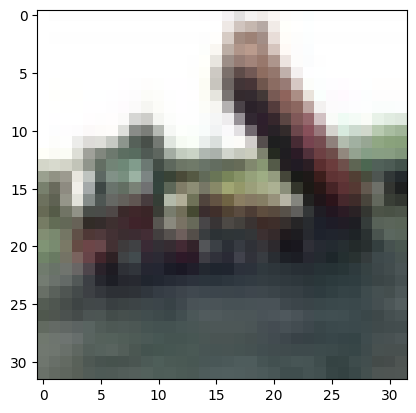

In [ ]:
plt.imshow(x_train[2])

In [5]:
print(x_train.shape)
print(x_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [6]:
#Normalization
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

In [7]:
#Modal / Data Parameters
num_classes = 10
input_shape = (32, 32, 3)

#Convert class vectors to binary class matrix
y_train = keras.utils.to_categorical(Y_train,num_classes=num_classes)
y_test = keras.utils.to_categorical(Y_test,num_classes=num_classes)

# Model Build

In [8]:
model = Sequential()

model.add(Conv2D(filters=16, kernel_size=(3,3), padding='same', input_shape=input_shape, activation='relu'))
model.add(BatchNormalization())
model.add(Conv2D(filters=16, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(Conv2D(filters=32, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(Conv2D(filters=64, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(Conv2D(filters=128, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())

model.add(Dense(128))
model.add(Activation('relu'))

model.add(Dense(128))
model.add(Activation('relu'))

model.add(Dense(10,activation='softmax'))

/Users/omarjibreen/College/Spring 2026/CSC_4260/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Augmentation

In [9]:
#Augmentation
datagen = ImageDataGenerator(rotation_range=15, # rotate the image 15 degrees
                             width_shift_range=0.1, # Shift the pic width by a max of 10%
                             height_shift_range=0.1, # Shift the pic height by a max of 10%
                             shear_range=0.1, # Shear means cutting away part of the image (max 10%)
                             zoom_range=0.1, # Zoom in by 10% max
                             horizontal_flip=True, # Allow horizontal flipping
                             fill_mode='nearest' # Fill in missing pixels with the nearest filled value
                              )
datagen.fit(x_train)

In [10]:
augmented_flow = datagen.flow(x_train, y_train, batch_size=64)

## Fitting Model

In [11]:
batch_size = 64
epochs = 40

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights = True)

model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=["accuracy"])

model.fit(augmented_flow,
          epochs=epochs,
          validation_data=(x_test, y_test),
          callbacks=[early_stop])

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 35s 42ms/step - accuracy: 0.3991 - loss: 1.6338 - val_accuracy: 0.5422 - val_loss: 1.2616
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.5378 - loss: 1.2813 - val_accuracy: 0.5800 - val_loss: 1.2185
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 45s 57ms/step - accuracy: 0.6051 - loss: 1.1156 - val_accuracy: 0.6014 - val_loss: 1.1770
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.6443 - loss: 1.0094 - val_accuracy: 0.6731 - val_loss: 0.9627
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.6685 - loss: 0.9469 - val_accuracy: 0.6904 - val_loss: 0.9062
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 40s 52ms/step - accuracy: 0.6883 - loss: 0.8905 - val_accuracy: 0.6740 - val_loss: 0.9633
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.7015 - loss: 0.8568 - val_accuracy: 0.7200 - val_loss: 0.8305
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.7127 - loss: 0.8215 - 

In [12]:
y_pred = model.predict(x_test)
print(y_test[1])
print(y_pred[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
[3.1469943e-05 7.8700721e-02 1.5949217e-06 2.3493071e-06 1.0928027e-07
 7.8376388e-07 1.4115146e-05 2.2449089e-07 9.2106074e-01 1.8785193e-04]


In [13]:
y_pred=np.argmax(y_pred,1)
y_test=np.argmax(y_test,1)
print(y_pred[1], y_test[1])


8 8


# Checking Accuracy & Other Metrics

## Confusion Matrix

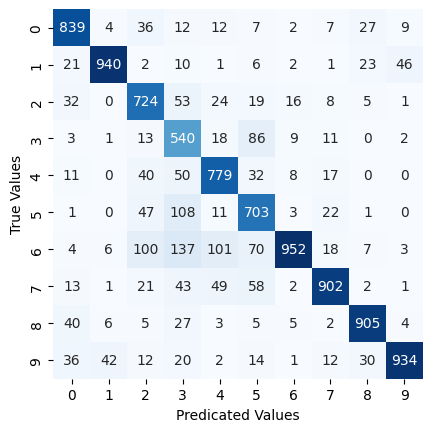

In [14]:
mat = confusion_matrix(Y_test, y_pred)

sns.heatmap(mat.T,square=True,annot=True,cbar=False,cmap=plt.cm.Blues, fmt='.0f')
plt.xlabel('Predicated Values')
plt.ylabel('True Values')
plt.show()

## Loss & Validation Loss

In [15]:
summary = pd.DataFrame(model.history.history)


<Axes: >

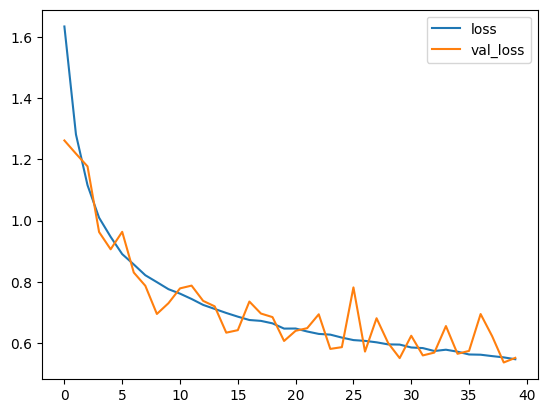

In [16]:
summary[["loss", "val_loss"]].plot()

## Accuracy & Validation Accuracy

<Axes: >

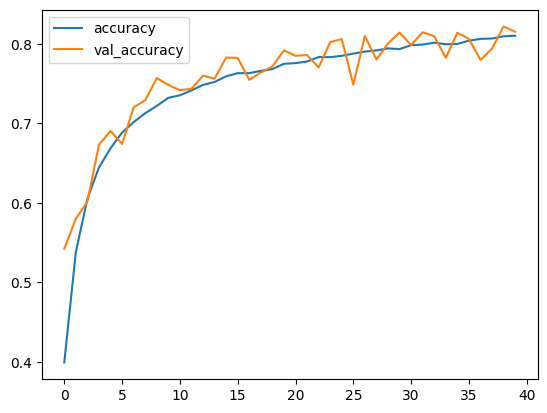

In [17]:
summary[["accuracy", "val_accuracy"]].plot()

Saving Model to Files

In [19]:
model.save("jibreencifar10_model.keras")
model.save("jibreencifar10_model.h5")

# Manual Testing

In [20]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

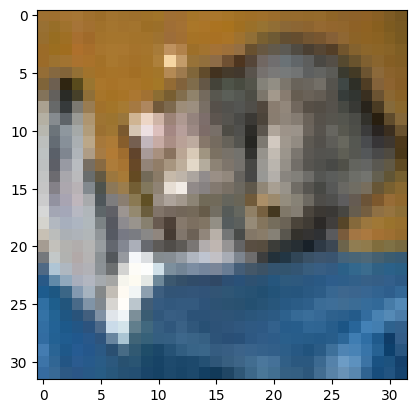

In [23]:
plt.imshow(x_test[0])

In [ ]:
pred = model.predict(x_test[0:1])
pred_class = np.argmax(pred)

print(pred_class)
print(class_names[pred_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
3
cat
